In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.close()
import matplotlib as mpl
from matplotlib import gridspec

from brokenaxes import brokenaxes

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
import os
import pickle5 as pickle
import csv
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter

import import_ipynb
import ipynb.fs.full.ssiProjectModule2 as ssiMod

from tqdm.notebook import tqdm
import sys

import importlib as imp
imp.reload(ssiMod)

from scipy.stats import wilcoxon as w
from scipy.special import factorial
from scipy.stats import circmean
from scipy.stats import circstd
import math
import statsmodels.stats.api as sms

from multiprocessing import Pool
from functools import partial

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from datetime import datetime
import bisect


main_dir = '/home/cparis/00PhD/DS_PCBreview/'


def plot_circle(ax, angle_deg, R=1.0):
    # Convert angle to radians
    theta = np.deg2rad(angle_deg)
    
    # Arrow endpoint
    x = R * np.cos(theta)
    y = R * np.sin(theta)

    
    # Draw circle of radius R
    circle = plt.Circle((0, 0), R, fill=False)
    ax.add_patch(circle)

    
    # Formatting
    ax.set_aspect('equal', adjustable='datalim')  # tightly fit
    ax.autoscale_view()   
#     ax.set_xlim(-1.2*R, 1.2*R)
#     ax.set_ylim(-1.2*R, 1.2*R)
    ax.axhline(0,  alpha = 0.5)
    ax.axvline(0,  alpha = 0.5)
    ax.grid(False)
    ax.axis('off')

#     plt.show()

def draw_arrow(ax, x0,y0, th, l):
        # Draw arrow from origin
    ax.arrow(x0, y0, l*np.cos(np.deg2rad(th)), l*np.sin(np.deg2rad(th)), 
             length_includes_head=True,
             head_width=0.02, 
             head_length=0.02,
             facecolor = 'k')

def draw_ellipse(ax, a, b):
    # Parameter t
    t = np.linspace(0, 2*np.pi, 400)
    
    # Ellipse parametric equations
    x = a * np.cos(t)
    y = b * np.sin(t)
    
    # Plot
#     plt.figure()
    plt.plot(x, y, linestyle='dashed', alpha = 0.5)
    plt.gca().set_aspect('equal', adjustable='box')
    
    # Axes and grid
#     plt.title(f"Ellipse with radii a={a}, b={np.around(b,2)}")

def complex_from_polar(k, theta):
    return k * np.exp(1j * np.deg2rad(theta))

def flow_ellipse_axis(x,y, Ry=1):
#     returns the minor ellipse axis along the x axis
    if y==Ry:
        return Ry/2  #arbitrary value
    else:
        return x/np.sqrt(1.-(y/Ry)**2)

def ellipse_slope_in_xy(x,y,Rx,Ry):
    if Rx==0:
        return -np.inf*np.sign(y)  #case where ellipse is collapsed onto a segment [-Ry, Ry]
    elif y==0:
        return -np.sign(x)*np.inf
    else:
        return -(x/y)*(Ry/Rx)**2 


def flow_in_point_of_ellipse_horizontal(x,z, x_ax, z_ax, arrow_len, hor_comp_th):
#     NOTE: MODIFICATION OF LENGTH:
#           Consider 2 arrows at same source point, one pointing towards a pole, other pointing away from it
#           The arrow pointing towards will appear shorter when projected because of sphere curvature
#           This is coded in "np.sign(phi*x)*delta_arc" term

    slope_h = ellipse_slope_in_xy(x,z, a_ax, z_ax)
    if np.abs(slope_h)!=np.inf:
        mod_dir_h = np.arctan(slope_h)+(1-np.sign(hor_comp_th))*np.pi/2*np.abs(np.sign(hor_comp_th))
    else: mod_dir_h = np.pi/2 - np.pi/2*np.sign(hor_comp_th)
    lmbda = np.arctan(z/x) if x!=0 else 0.
    phi = np.arccos(np.sqrt(x**2+z**2)/R)
    hor_flow_amp =  np.abs(arrow_len)*np.sqrt(1-np.cos(phi-np.sign(hor_comp_th*x)*delta_arc)**2*np.cos(lmbda)**2)
    print(mod_dir_h)
    return mod_dir_h, hor_flow_amp

def optic_flow_mod(theta, x0, z0):
    # horizontal and vertical components of stimulus direction 
    #(along naso-temporal and dorso-ventral axes, respectively)
    hor_comp_th,vert_comp_th = np.cos(theta), np.sin(theta)
    hor_arrow_len, vert_arrow_len = 0.2*hor_comp_th, 0.2*vert_comp_th

    # Naso-temporal flow ellipse - along x axis (ah=1)
    hor_a, hor_b = 1, flow_ellipse_axis(z0,x0)
    vert_b, vert_a = 1, flow_ellipse_axis(x0,z0)
    
    for x in [x0]:
        z = hor_b*np.sqrt(1.-(x/hor_a)**2)
        th1, l1 = flow_in_point_of_ellipse_horizontal(x,z, hor_a, hor_b, hor_arrow_len, hor_comp_th)
    for z in [z0]:
        x = vert_a*np.sqrt(1.-(z/vert_b)**2)
        th2, l2 = flow_in_point_of_ellipse_vertical(x,z, vert_a, vert_b, vert_arrow_len, vert_comp_th)
    final = l1*np.exp(1j*th1) + l2*np.exp(1j*th2)
    return np.sqrt(final.real**2+final.imag**2), np.rad2deg(np.angle(final))%360

def flow_ellipse_axis(x,y, Ry=1):
#     returns the minor ellipse axis along the x axis
    if y==Ry:
        return Ry/2  #arbitrary value
    else:
        return x/np.sqrt(1.-(y/Ry)**2)

def ellipse_slope_in_xy(x,y,Rx,Ry):
    if Rx==0:
        return -np.inf*np.sign(y)  #case where ellipse is collapsed onto a segment [-Ry, Ry]
    elif y==0:
        return -np.sign(x)*np.inf
    else:
        return -(x/y)*(Ry/Rx)**2 


def flow_in_point_of_ellipse(x,z, x_ax, z_ax, flow_parallel_comp, which, delta_arc = np.deg2rad(15)):
#     NOTE: MODIFICATION OF LENGTH:
#           Consider 2 arrows at same source point, one pointing towards a pole, other pointing away from it
#           The arrow pointing towards will appear shorter when projected because of sphere curvature
#           This is coded in "np.sign(phi*x)*delta_arc" term
    lmbda = np.arctan(z/x) if x!=0 else -np.sign(z)*np.pi
    phi = np.arccos(np.sqrt(x**2+z**2)/R)
    slope_h = ellipse_slope_in_xy(x,z, x_ax, z_ax)
    if np.abs(slope_h)!=np.inf:
        new_theta = np.arctan(slope_h)+(1+np.sign(flow_parallel_comp*x*z))*np.pi/2*np.abs(np.sign(flow_parallel_comp))
        if which=='h':
            new_theta = -new_theta+np.pi/2
    elif np.abs(slope_h)==np.inf and which=='h': 
        new_theta = np.pi/2 - np.pi/2*np.sign(flow_parallel_comp)
#         new_theta = np.pi/2*np.sign(flow_parallel_comp)

    elif np.abs(slope_h)==np.inf and which=='v': 
        new_theta = np.pi/2*np.sign(flow_parallel_comp)
        
    amplitude_mod = np.sqrt(1.-np.cos(phi-np.sign(flow_parallel_comp*z)*delta_arc)**2\
                            *np.sin(lmbda+np.sign(flow_parallel_comp*x)*delta_arc)**2) 

#     if which=='v':
#         amplitude_mod = np.sqrt(1-np.cos(phi-np.sign(flow_parallel_comp*z)*delta_arc)**2*np.cos(lmbda)**2)        
#     elif which=='h':
#         amplitude_mod = np.sqrt(1-np.cos(phi-np.sign(flow_parallel_comp*z)*delta_arc)**2*np.cos(lmbda)**2) 
    return np.abs(flow_parallel_comp)*amplitude_mod, np.rad2deg(new_theta)


def FTVM_dx(th, a, th_0, s, baseline, g):           #indexed with 'ftvm'
    '''Modified Von Mises function\n Parameters Area, mean, concentration, baseline, flatness\n g = 0 gives Von Mises function'''
    '''This version computes the FTVM on a non-uniform dx support, preserving the area under the curve'''
#     get average bins size centered in th[i]: dx[i] = (x[i+1]-x[i-1])/2
    delta_th = (180-np.abs(180-np.abs((np.roll(th, -1) - np.roll(th, 1)))))/2  
#     print(delta_th)
#     get ftvm function value at th[i]
    ftvm_f = np.exp(np.float64((np.cos(np.deg2rad(th-th_0-g*np.sin(np.deg2rad(th-th_0))))-1)/s))
    
    res = (a*ftvm_f/ np.sum(ftvm_f*delta_th/(360/36)) + baseline) 
    return res+np.any(res<0.)*1e10


def direction_deformation(vector, x0,z0, R=1, arrow_len=0.15):
    vert_b, vert_a = R, flow_ellipse_axis(x0,z0)
    hor_a, hor_b = R, flow_ellipse_axis(z0,x0)
    
    for theta in np.deg2rad(vector):
        # upward arrow at (0,0)
        ax.arrow(0, 0, arrow_len*np.cos(theta),arrow_len*np.sin(theta), 
             head_width=arrow_len/5, head_length=arrow_len/3, fc='k', ec='k')
        l_mod_z, th_mod_z = flow_in_point_of_ellipse(x0,z0, vert_a, vert_b, arrow_len*np.sin(theta), 'v')
        l_mod_x, th_mod_x = flow_in_point_of_ellipse(z0,x0, hor_b, hor_a, arrow_len*np.cos(theta), 'h')

        resultant = l_mod_x*np.exp(1j*np.deg2rad(th_mod_x)) + l_mod_z*np.exp(1j*np.deg2rad(th_mod_z))
        final_arr = np.append(final_arr, resultant)

    final_l, final_th = np.sqrt(final_arr.real**2+final_arr.imag**2), np.rad2deg(np.angle(final_arr))%360 

#     print(final_th.shape)
    new_vector = final_l*np.exp(1j*np.deg2rad(final_th))
    return final_l, final_th, new_vector

/home/cparis/anaconda3/lib/python3.7/site-packages/statsmodels/compat/pandas.py:49: FutureWarning: The Panel class is removed from pandas. Accessing it from the top-level namespace will also be removed in the next version
  data_klasses = (pandas.Series, pandas.DataFrame, pandas.Panel)


0
450
900
1350
0
450
900
1350
(1800,)


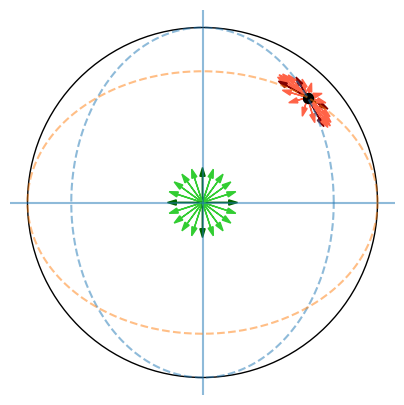

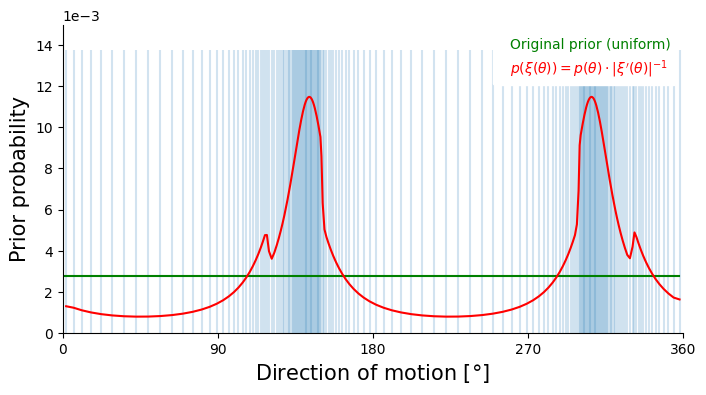

In [8]:
R=1
theta = np.deg2rad(-45)
hor_comp_th,vert_comp_th = np.cos(theta), np.sin(theta)
arrow_len = 0.2
delta_arc = np.deg2rad(10)

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.left'] = False
mpl.rcParams['axes.spines.bottom'] = False
# circle and vertical ellipse
x0, z0 = 0.6,0.6
vert_b, vert_a = 1, flow_ellipse_axis(x0,z0)
hor_a, hor_b = 1, flow_ellipse_axis(z0,x0)

fig, ax = plt.subplots(figsize=(5, 5))

plot_circle(ax, 90, 1)
draw_ellipse(ax, vert_a, vert_b)
draw_ellipse(ax, hor_a, hor_b)


# # upward arrow at (x0,z0)
# ax.arrow(0, 0, arrow_len*np.cos(theta),arrow_len*np.sin(theta), 
#          head_width=0.03, head_length=0.05, fc='k', ec='k')

# point
ax.scatter(x0, z0, s=50, c='k')
stim_step = 2
fine_stim = np.arange(0,360,stim_step/10)
stim = np.arange(0,360,stim_step)
#------uniform prior-----
th_prior = np.ones_like(stim)/(np.ones_like(stim)*stim_step).sum()
# -----------------------
arrow_len = 0.15
mod_prior = np.array([])

final_arr = np.array([])
for idx, theta in enumerate(np.deg2rad(fine_stim)):
    # upward arrow at (0,0)
    if idx % 90==0:
        if idx%(fine_stim.size//4)==0:
            print(idx)
            arrowcolor='darkgreen'
        else: arrowcolor='limegreen'
        ax.arrow(0, 0, arrow_len*np.cos(theta),arrow_len*np.sin(theta), 
             head_width=0.03, head_length=0.05, fc=arrowcolor, ec=arrowcolor)
    l_mod_z, th_mod_z = flow_in_point_of_ellipse(x0,z0, vert_a, vert_b, arrow_len*np.sin(theta), 'v')
    l_mod_x, th_mod_x = flow_in_point_of_ellipse(z0,x0, hor_b, hor_a, arrow_len*np.cos(theta), 'h')
    
    resultant = l_mod_x*np.exp(1j*np.deg2rad(th_mod_x)) + l_mod_z*np.exp(1j*np.deg2rad(th_mod_z))
    final_arr = np.append(final_arr, resultant)

final_l, final_th = np.sqrt(final_arr.real**2+final_arr.imag**2), np.rad2deg(np.angle(final_arr))%360 

for idx, arr in enumerate(final_l*np.exp(1j*np.deg2rad(final_th))):
    if idx % 90==0:
        if idx%(fine_stim.size//4)==0:
            print(idx)
            arrowcolor='maroon'
        else: 
            arrowcolor='tomato'
    else: continue
    ax.arrow(x0, z0, arr.real, arr.imag,
         head_width=0.03, head_length=0.05, fc=arrowcolor, ec=arrowcolor)
# (x0,z0) point
ax.scatter(x0, z0, s=50, c='k',)
# plt.savefig(main_dir+f'1Optic_flow_direction_distortion_[{x0,z0}].jpg', bbox_inches = 'tight', dpi = 300)
print(final_th.shape)

roll_idx = final_th.argmin()

d_xi = np.roll(np.abs(180-np.abs(180-np.abs((np.roll(np.roll(final_th, -roll_idx), -1) \
                                      - np.roll(np.roll(final_th, -roll_idx), 1)))))/2, roll_idx)

xi_stim = np.roll(final_th, -roll_idx).reshape(-1,int(fine_stim.size/stim.size)).mean(axis=1)
avg_d_xi = np.gradient(xi_stim)/stim_step
xi_prior = th_prior/avg_d_xi

hist_prior = np.histogram(np.roll(final_th, -roll_idx), range = (0,360), bins = 180, density = True)[0]
mpl.rcParams['axes.spines.left'] = True
mpl.rcParams['axes.spines.bottom'] = True
# plt.figure(figsize = (5,5))
# plt.plot(stim, xi_stim)
# plt.xlabel(r'Direction $\theta$', size = 15)
# plt.ylabel(r'Direction deformation $\xi(\theta)$', size = 15)
# plt.xticks(np.arange(0,361, 90))
# plt.yticks(np.arange(0,361, 90))
# plt.xlim(0,360)
# plt.ylim(0,360)
# plt.savefig(main_dir+f'2theta_v_xi(theta)_[{x0,z0}].jpg', bbox_inches = 'tight', dpi = 300)


plt.figure(figsize = (8,4))


# plt.title(r'Prior p($\xi(\theta))=\frac{p(\theta)}{|\xi^{\prime}(\theta)|}$', size = 15)

plt.plot(stim, th_prior, color = 'green',label = 'Original prior (uniform)')

plt.plot(xi_stim, xi_prior, color = 'red', label = r'$p(\xi(\theta)) = p(\theta)\cdot |\xi^{\prime}(\theta)|^{-1}$')
# plt.plot(stim, hist_prior, color = 'grey', label = r'Norm. histogram of $\xi(\theta)$')
plt.xlabel(r'Direction of motion [$\degree$]', size = 15)
plt.ylabel('Prior probability', size = 15)
plt.vlines(xi_stim, ymin=0,  ymax=xi_prior.max()*1.2, alpha = 0.2, zorder=0)
plt.ticklabel_format(axis='y', style='sci', scilimits=(-3, -3))
plt.xticks(np.arange(0,361,90))
plt.xlim(0,360)
plt.ylim(0,0.015)
leg = plt.legend(handlelength = 0, labelcolor = 'linecolor', edgecolor = 'w', facecolor = 'white',framealpha=1)
leg.set_zorder(10)
# plt.savefig(main_dir+f'3Priors_[{x0,z0}].jpg', bbox_inches = 'tight', dpi = 300)


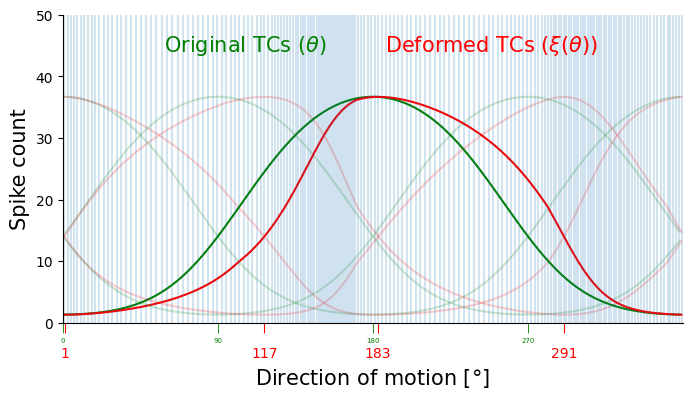

In [3]:
a,s,b,g = 600, 0.6, 0.01, 25  
og_tc_quad = np.array([FTVM_dx(stim, a, mu, s, b, g) for mu in [0,90,180,270]])
# mod_tc_quad = np.array([FTVM_dx(final_th, a, mu, s, b, g) for mu in [0,90,180,270]])

plt.figure(figsize=(8,4))

for i in range(og_tc_quad.shape[0]):
    if i == 2:
        label1, label2, alpha = r'Original TCs ($\theta$)', r'Deformed TCs ($\xi(\theta)$)', 1  
    else: 
        label1, label2, alpha = '_nolegend_', '_nolegend_', 0.2
    plt.plot(stim, og_tc_quad[i] + 0.025, color='green', alpha=alpha, label=label1)
    plt.plot(xi_stim, og_tc_quad[i], color='red', alpha=alpha, label=label2)

plt.xlim(0,360)

ax = plt.gca()
ax.tick_params(axis='x', size = 7, labelsize = 10, which='major', color = 'red', labelcolor = 'red', pad=10)
ax.tick_params(axis='x', size = 7, labelsize = 5, which='minor', color = 'green', labelcolor = 'green')

ax.set_xticks(np.around(xi_stim[np.array([np.where(stim==v)[0][0] for v in [0,90,180,270]])]))
ax.set_xticks(np.arange(0,360,90), np.arange(0,360,90), minor = True)
plt.ylim(0,50)
plt.yticks(np.arange(0,51,10))
plt.vlines(xi_stim, ymin=0,  ymax=50, alpha = 0.2)

plt.xlabel('Direction of motion [$\degree$]', size = 15)
plt.ylabel('Spike count', size = 15)


leg = plt.legend(handlelength=0, labelcolor = 'linecolor', frameon = 0, \
                 fontsize = 15, ncol=2, loc = 'upper center')
# plt.savefig(main_dir+f'4TuningCurves__theta_v_xi(theta)_[{x0,z0}].jpg', bbox_inches = 'tight', dpi = 300)


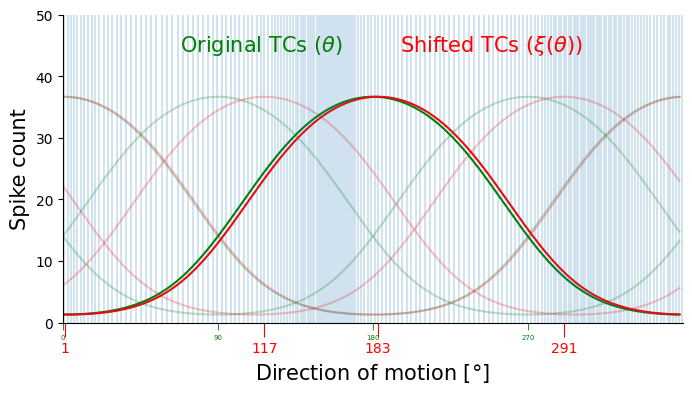

In [4]:
a,s,b,g = 600, 0.6, 0.01, 25  

mod_mu = np.around(xi_stim[np.array([np.where(stim==v)[0][0] for v in [0,90,180,270]])])
og_tc_quad = np.array([FTVM_dx(stim, a, mu, s, b, g) for mu in [0,90,180,270]])
mod_tc_quad = np.array([FTVM_dx(stim, a, mu, s, b, g) for mu in mod_mu])

plt.figure(figsize=(8,4))

for i in range(og_tc_quad.shape[0]):
    if i == 2:
        label1, label2, alpha = r'Original TCs ($\theta$)', r'Shifted TCs ($\xi(\theta)$)', 1  
    else: 
        label1, label2, alpha = '_nolegend_', '_nolegend_', 0.25
    plt.plot(stim, og_tc_quad[i], color='green', alpha=alpha, label=label1)
    plt.plot(stim, mod_tc_quad[i], color='red', alpha=alpha, label=label2)

plt.xlim(0,360)

ax = plt.gca()
ax.tick_params(axis='x', size = 10, labelsize = 10, which='major', color = 'red', labelcolor = 'red')
ax.tick_params(axis='x', size = 5, labelsize = 5, which='minor', color = 'green', labelcolor = 'green')

ax.set_xticks(mod_mu)
ax.set_xticks(np.arange(0,360,90), np.arange(0,360,90), minor = True)
plt.ylim(0,50)
plt.yticks(np.arange(0,51,10))
plt.vlines(xi_stim, ymin=0,  ymax=50, alpha = 0.2)

plt.xlabel('Direction of motion [$\degree$]', size = 15)
plt.ylabel('Spike count', size = 15)


leg = plt.legend(handlelength=0, labelcolor = 'linecolor', frameon = 0, \
                 fontsize = 15, ncol=2, loc = 'upper center')
# plt.savefig(main_dir+f'6ShiftedTuningCurves__theta_v_xi(theta)_[{x0,z0}].jpg', bbox_inches = 'tight', dpi = 300)

In [5]:
import ssiProjectModule2 as ssiMod
imp.reload(ssiMod)

importing Jupyter notebook from ssiProjectModule2.ipynb
importing Jupyter notebook from ssiProjectModule2.ipynb


<module 'ssiProjectModule2' from 'ssiProjectModule2.ipynb'>

In [6]:
mod_stim = np.copy(xi_stim)
mod_tcs = np.copy(og_tc_quad)
mod_prior = np.copy(xi_prior)


cissi_mod = ssiMod.MC_CiSSI(mod_stim, mod_prior, mod_tcs)
cissi_og = ssiMod.MC_CiSSI(stim, th_prior, og_tc_quad)

ssi_mod = ssiMod.MC_SSI_w_PRIOR(mod_stim, mod_tcs, mod_prior)
ssi_og = ssiMod.MC_SSI_w_PRIOR(stim, og_tc_quad, th_prior)

In [7]:
mod_stim = np.copy(xi_stim)
shift_tcs = np.copy(mod_tc_quad)
mod_prior = np.copy(xi_prior)


shift_cissi_mod = ssiMod.MC_CiSSI(stim, mod_prior, shift_tcs)

shift_ssi_mod = ssiMod.MC_SSI_w_PRIOR(stim, shift_tcs, mod_prior)

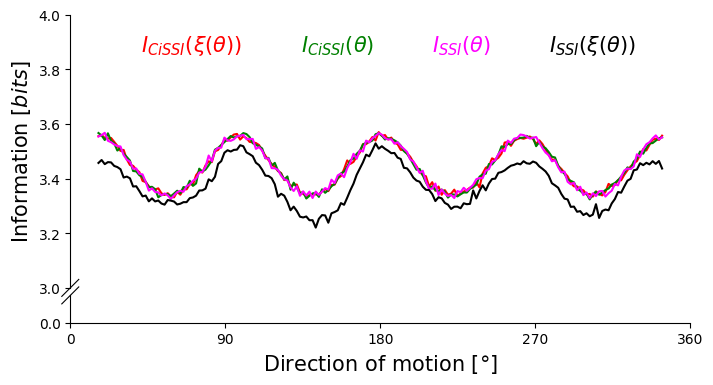

In [8]:
plt.figure(figsize = (8,4))
plt.rcParams['xtick.labelsize']=10
plt.rcParams['ytick.labelsize']=10

bax = brokenaxes(ylims=((0,0.1),(3,4)), hspace=0.05)

bax.plot(stim, cissi_mod, color = 'red', label = r'$I_{CiSSI}(\xi(\theta))$')
bax.plot(stim, cissi_og, color = 'green', label = r'$I_{CiSSI}(\theta)$')
bax.plot(stim, ssi_og, color = 'magenta', label = r'$I_{SSI}(\theta)$')

bax.plot(stim, ssi_mod, color = 'k', label = r'$I_{SSI}(\xi(\theta))$')

bax.axs[0].set_yticks(np.arange(3,4.1,0.2))

bax.axs[1].set_xticks(np.arange(0,361,90))
bax.axs[1].set_xlim(0,360)

bax.axs[1].set_xlabel(r'Direction of motion [$\degree$]', size = 15)
bax.axs[0].set_ylabel(r'Information [$bits$]', size= 15)
leg = bax.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, \
                 fontsize = 15, ncol = 4, loc = 'upper center')


# plt.savefig(main_dir+f'5SSI_v_CiSSI__theta_v_xi(theta)_[{x0,z0}].jpg', bbox_inches = 'tight', dpi = 300)


In [9]:
def plot_circle(ax, angle_deg, R=1.0):
    # Convert angle to radians
    theta = np.deg2rad(angle_deg)
    
    # Arrow endpoint
    x = R * np.cos(theta)
    y = R * np.sin(theta)

    
    # Draw circle of radius R
    circle = plt.Circle((0, 0), R, fill=False)
    ax.add_patch(circle)

    
    # Formatting
    ax.set_aspect('equal', adjustable='datalim')  # tightly fit
    ax.set_xlim(-1.01*R, 1.01*R)
    ax.set_ylim(-1.01*R, 1.01*R)
    ax.axhline(0,  alpha = 0.5)
    ax.axvline(0,  alpha = 0.5)
    ax.grid(False)
    ax.axis('off')

0
450
900
1350
0 maroon
450 maroon
900 maroon
1350 maroon


Text(-0.35, 1.1, 'B)')

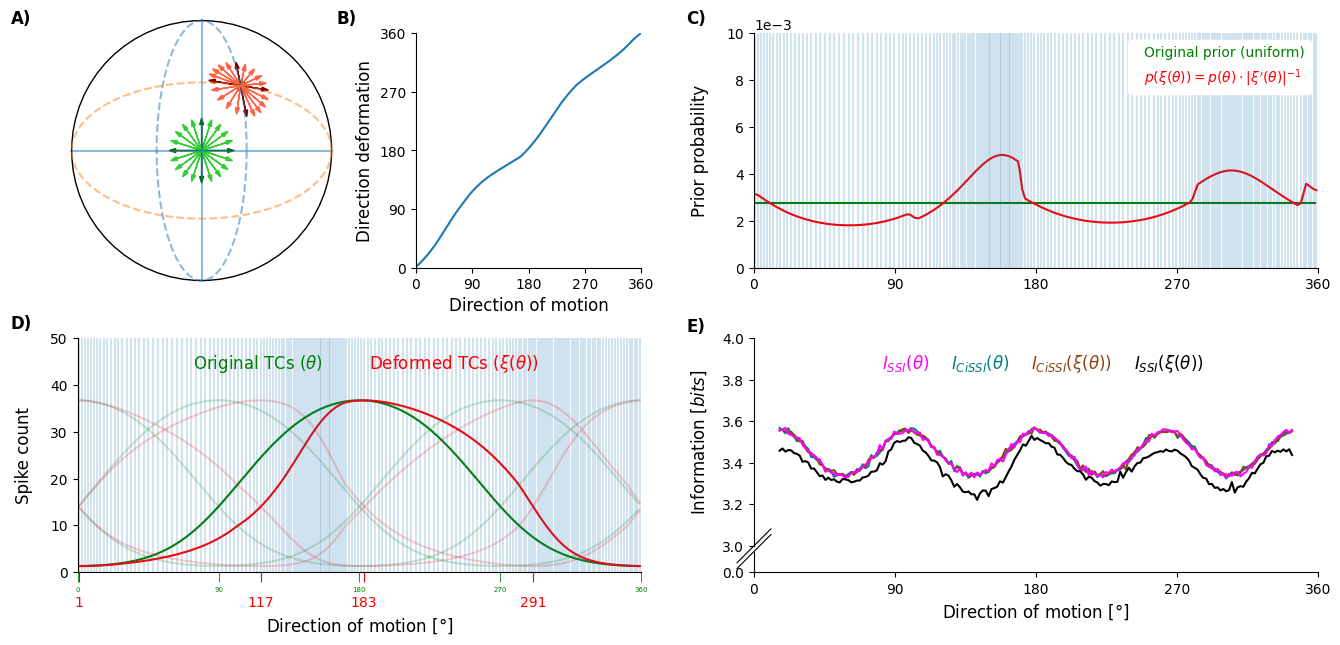

In [10]:
labelsize = 12

fig = plt.figure(figsize=(16,7))

# gs = gridspec.GridSpec(2,4,hspace=0.2, wspace = 0.5)
# make first row taller to match ax2's height
gs = gridspec.GridSpec(2, 4, hspace=0.3, wspace=0.5, height_ratios=[1,1])
# =====================================================
# PANEL 1 (left) (square) — geometry + arrows  
# =====================================================
ax0 = fig.add_subplot(gs[0,0])
# ax0.set_box_aspect(1)


plot_circle(ax0, 90, 1)
draw_ellipse(ax0, vert_a, vert_b)
draw_ellipse(ax0, hor_a, hor_b)
arrow_len = 0.2
ax0.scatter(x0, z0, s=50, c='k')
final_arr=np.array([])
# uniform arrows
for idx, theta in enumerate(np.deg2rad(fine_stim)):
    # upward arrow at (0,0)
    if idx % 90==0:
        if idx%(fine_stim.size//4)==0:
            print(idx)
            arrowcolor='darkgreen'
        else: arrowcolor='limegreen'
        ax0.arrow(0, 0, arrow_len*np.cos(theta),arrow_len*np.sin(theta), 
             head_width=0.03, head_length=0.05, fc=arrowcolor, ec=arrowcolor)
    l_mod_z, th_mod_z = flow_in_point_of_ellipse(x0,z0, vert_a, vert_b, arrow_len*np.sin(theta), 'v')
    l_mod_x, th_mod_x = flow_in_point_of_ellipse(z0,x0, hor_b, hor_a, arrow_len*np.cos(theta), 'h')
    
    resultant = l_mod_x*np.exp(1j*np.deg2rad(th_mod_x)) + l_mod_z*np.exp(1j*np.deg2rad(th_mod_z))
    final_arr = np.append(final_arr, resultant)

final_l, final_th = np.sqrt(final_arr.real**2+final_arr.imag**2), np.rad2deg(np.angle(final_arr))%360 

# arrows already computed externally
for idx, arr in enumerate(final_l*np.exp(1j*np.deg2rad(final_th))):
    if idx % 90==0:
        if idx%(fine_stim.size//4)==0:
            print(idx, 'maroon')
            arrowcolor='maroon'
        else: 
            arrowcolor='tomato'
    else: continue
    ax0.arrow(x0, z0, arr.real, arr.imag,
         head_width=0.03, head_length=0.05, fc=arrowcolor, ec=arrowcolor)
ax0.set_xticks([])
ax0.set_yticks([])
# =====================================================
# PANEL 1 (right) (square) — \xi(\theta)  
# =====================================================
ax1 = fig.add_subplot(gs[0,1])
# ax1.set_box_aspect(1)
ax1.plot(stim, xi_stim)
ax1.set_xlabel(r'Direction of motion', size = labelsize)
ax1.set_ylabel(r'Direction deformation', size = labelsize)
ax1.set_xticks(np.arange(0,361, 90))
ax1.set_yticks(np.arange(0,361, 90))
ax1.set_xlim(0,360)
ax1.set_ylim(0,360)

# =====================================================
# PANEL 2 — prior transformation
# =====================================================
ax2 = fig.add_subplot(gs[0,2:])

ax2.plot(stim, th_prior, color='green', label='Original prior (uniform)')
ax2.plot(xi_stim, xi_prior, color='red',
         label=r'$p(\xi(\theta)) = p(\theta)\cdot |\xi^{\prime}(\theta)|^{-1}$')

ax2.vlines(xi_stim, ymin=0, ymax=0.01, alpha=0.2)

# ax2.set_xlabel(r'Direction of motion [$\degree$]', size=labelsize)
ax2.set_ylabel('Prior probability', size=labelsize)
ax2.yaxis.set_label_coords(-0.08, 0.5)

ax2.set_xticks(np.arange(0,361,90))
ax2.set_xlim(0,360)
ax2.set_ylim(0,0.01)

ax2.ticklabel_format(axis='y', style='sci', scilimits=(-3,-3))

leg = ax2.legend(handlelength=0,
                 labelcolor='linecolor',
                 edgecolor='w',
                 facecolor='white',
                 framealpha=1)

ax2.text(-0.12, 1.1, 'C)', ha='left', va='top', transform=ax2.transAxes, fontweight='bold', fontsize = labelsize)
# =====================================================
# PANEL 3 — tuning curves
# =====================================================
ax3 = fig.add_subplot(gs[1,:2])

for i in range(og_tc_quad.shape[0]):

    if i == 2:
        label1 = r'Original TCs ($\theta$)'
        label2 = r'Deformed TCs ($\xi(\theta)$)'
        alpha = 1
    else:
        label1 = '_nolegend_'
        label2 = '_nolegend_'
        alpha = 0.2

    ax3.plot(stim, og_tc_quad[i] + 0.025,
             color='green', alpha=alpha, label=label1)

    ax3.plot(xi_stim, og_tc_quad[i],
             color='red', alpha=alpha, label=label2)

ax3.set_xlim(0,360)
ax3.set_ylim(0,50)

ax3.set_xlabel('Direction of motion [$\degree$]', size=labelsize)
ax3.set_ylabel('Spike count', size=labelsize)

ax3.set_yticks(np.arange(0,51,10))

ax3.vlines(xi_stim, ymin=0, ymax=50, alpha=0.2)

ax3.tick_params(axis='x', size=7, labelsize=10,
                which='major', color='red', labelcolor='red', pad=10)

ax3.tick_params(axis='x', size=7, labelsize=5,
                which='minor', color='green', labelcolor='green')

ax3.set_xticks(
    np.around(xi_stim[np.array([np.where(stim==v)[0][0] for v in [0,90,180,270]])])
)

ax3.set_xticks(np.arange(0,361,90), np.arange(0,361,90), minor=True)
ax3.yaxis.set_label_coords(-0.08, 0.5)
leg = ax3.legend(handlelength=0,
                 labelcolor='linecolor',
                 frameon=0,
                 fontsize=12,
                 ncol=2,
                 loc='upper center')

ax3.text(-0.12, 1.1, 'D)', ha='left', va='top', transform=ax3.transAxes, fontweight='bold', fontsize = labelsize)

# =====================================================
# PANEL 4 — information comparison (broken axis)
# =====================================================
bax = brokenaxes(
    subplot_spec=gs[1,2:],
    ylims=((0,0.1),(3,4)),
    hspace=0.05
)
bax.plot(stim, ssi_og, color='magenta', label=r'$I_{SSI}(\theta)$', zorder = 3)
bax.plot(stim, cissi_og, color='teal', label=r'$I_{CiSSI}(\theta)$', zorder = 1)
bax.plot(stim, cissi_mod, color='saddlebrown', label=r'$I_{CiSSI}(\xi(\theta))$', zorder = 2)
bax.plot(stim, ssi_mod, color='black', label=r'$I_{SSI}(\xi(\theta))$', zorder = 4)

bax.axs[0].set_yticks(np.arange(3,4.1,0.2))

bax.axs[1].set_xticks(np.arange(0,361,90))
bax.axs[1].set_xlim(0,360)

bax.axs[1].set_xlabel(r'Direction of motion [$\degree$]', size=labelsize)
bax.axs[0].set_ylabel(r'Information [$bits$]', size=labelsize)
bax.axs[0].yaxis.set_label_coords(-0.08, 0.5)

bax.legend(handlelength=0,
           labelcolor='linecolor',
           frameon=0,
           fontsize=labelsize,
           ncol=4,
           columnspacing = .5,
           loc='upper center')

bax.axs[0].text(-0.12, 1.1, 'E)', ha='left', va='top', \
                transform=bax.axs[0].transAxes, fontweight='bold', fontsize = labelsize)

# ax0.set_position([0.12, 0.632, 0.325, 0.325])  # [left, bottom, width, height]
# ax0.text(-0.265, 1.18, 'A)', ha='left', va='top', transform=ax0.transAxes, fontweight='bold', fontsize = labelsize)

ax0.set_position([0.015, 0.525, 0.375, 0.375])  # [left, bottom, width, height]
ax0.text(-0.227, 1.0375, 'A)', ha='left', va='top', transform=ax0.transAxes, fontweight='bold', fontsize = labelsize)
ax1.text(-0.35, 1.1, 'B)', ha='left', va='top', transform=ax1.transAxes, fontweight='bold', fontsize = labelsize)


# plt.savefig('Flow_CiSSi_v_SSI.jpg', dpi=400, bbox_inches='tight')

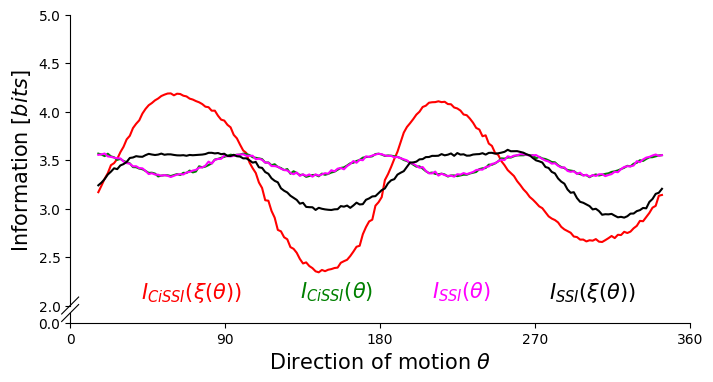

In [12]:
plt.figure(figsize = (8,4))
plt.rcParams['xtick.labelsize']=10
plt.rcParams['ytick.labelsize']=10

bax = brokenaxes(ylims=((0,0.1),(2,5)), hspace=0.05)

bax.plot(stim, shift_cissi_mod, color = 'red', label = r'$I_{CiSSI}(\xi(\theta))$')
bax.plot(stim, cissi_og, color = 'green', label = r'$I_{CiSSI}(\theta)$')
bax.plot(stim, ssi_og, color = 'magenta', label = r'$I_{SSI}(\theta)$')

bax.plot(stim, shift_ssi_mod, color = 'k', label = r'$I_{SSI}(\xi(\theta))$')

bax.axs[0].set_yticks(np.arange(2,5.1,0.5))

bax.axs[1].set_xticks(np.arange(0,361,90))
bax.axs[1].set_xlim(0,360)

bax.axs[1].set_xlabel(r'Direction of motion $\theta$', size = 15)
bax.axs[0].set_ylabel(r'Information [$bits$]', size= 15)
leg = bax.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, \
                 fontsize = 15, ncol = 4, loc = 'lower center')


# plt.savefig(main_dir+f'7SSI_v_CiSSI__theta_v_xi(theta)_[{x0,z0}].jpg', bbox_inches = 'tight', dpi = 300)


In [13]:
theta_step = 2
main_dir = '/home/cparis/00PhD/'

area_or_max = 'Area'
dat_dir_out = main_dir + f'Simulated Stretch/Analyze stretched quadruplets constrained by AREA or MAX/'

title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509_AREA.pkl'
# title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240506_MAX.pkl'


with open(dat_dir_out+title, 'rb') as rick:
    data_dict = pickle.load(rick)
print(data_dict.keys())


example = 201
bio_idx = np.where(data_dict['all_multipliers']==1)[0][0]
example_quad_pars = data_dict['all_quad_pars'][example,bio_idx]
example_quad_tc = np.array([ssiMod.FTVM_dx(stim, *pars) for pars in example_quad_pars])

dict_keys(['all_multipliers', 'all_quad_pars', 'all_quad_tc', 'all_ssis', 'all_quad_fwhm', 'exp_quad_list', 'all_quad_vm_fit_pars', 'all_quad_raw_mean_tcs', 'all_quad_raw_mean_stds', 'original_cell_idx_quads'])


### Empirical example quad

In [14]:
import ssiProjectModule2 as ssiMod
imp.reload(ssiMod)


importing Jupyter notebook from ssiProjectModule2.ipynb


<module 'ssiProjectModule2' from 'ssiProjectModule2.ipynb'>

# Modified quadruplets

In [ ]:
prev_len=0
def update_print(msg):
    global prev_len
    print(' ' * prev_len, end='\r')  # clear line
    print(msg, end='\r')
    prev_len = len(msg)

mod_stim = np.copy(xi_stim)
emp_tcs = np.copy(example_quad_tc)
mod_prior = np.copy(xi_prior)


og_ssi = np.array([])
mod_ssi = np.array([])
og_cissi = np.array([])
mod_cissi = np.array([])

for i, quad_pars in enumerate(tqdm(data_dict['all_quad_pars'][example])):

    
    tc_quad = np.array([ssiMod.FTVM_dx(stim, *pars) for pars in quad_pars])
    
    new_mod_ssi = np.atleast_2d(ssiMod.MC_SSI_w_PRIOR(mod_stim, tc_quad, mod_prior))
    mod_ssi = np.concatenate((mod_ssi, new_mod_ssi), axis=0) if mod_ssi.size else new_mod_ssi
    
    new_og_cissi = np.atleast_2d(ssiMod.MC_CiSSI(stim, th_prior, tc_quad))
    og_cissi = np.concatenate((og_cissi, new_og_cissi), axis=0) if og_cissi.size else new_og_cissi
    
    new_mod_cissi = np.atleast_2d(ssiMod.MC_CiSSI(mod_stim, mod_prior, tc_quad))
    mod_cissi = np.concatenate((mod_cissi, new_mod_cissi), axis=0) if mod_cissi.size else new_mod_cissi

# Shifted cells

In [211]:
prev_len=0
def update_print(msg):
    global prev_len
    print(' ' * prev_len, end='\r')  # clear line
    print(msg, end='\r')
    prev_len = len(msg)

mod_stim = np.copy(xi_stim)
emp_tcs = np.copy(example_quad_tc)
mod_prior = np.copy(xi_prior)

simple_pars = np.tile(np.array([600, 0, 0.6, 0.01, 25])[None,None,:], \
                      (len(data_dict['all_multipliers']), 4, 1))
simple_pars[:,:,1] = np.repeat(np.array([0,90,180,270])[None,:], len(data_dict['all_multipliers']), axis=0)
simple_pars[:,:,2] *= np.tile(data_dict['all_multipliers'][:,None], (1,4))



In [212]:
og_ssi = np.array([])
mod_ssi = np.array([])
og_cissi = np.array([])
mod_cissi = np.array([])

# for i, quad_pars in enumerate(tqdm(data_dict['all_quad_pars'][example])):

for i, quad_pars in enumerate(tqdm(simple_pars)):
# set the preferred directions (homogeneous and shifted according to deformation)
    shifted_mu = final_th[np.array([np.where(stim==i)[0][0] for i in [0,90,180,270]])*10]

# insert preferred directions into preexisting quadruplet parameters
    og_pars, shifted_pars = np.copy(quad_pars), np.copy(quad_pars)
    og_pars[:,1] = og_pars_mu
    shifted_pars[:,1] = shifted_mu

# generate quadruplets with homogenous and shifted preferred directions
    og_tc_quad = np.array([ssiMod.FTVM_dx(stim, *pars) for pars in og_pars])
    shifted_tc_quad = np.array([ssiMod.FTVM_dx(stim, *pars) for pars in shifted_pars])
    
# ssi with uniform prior and homogeneous PDs
    new_og_ssi = np.atleast_2d(ssiMod.MC_SSI_w_PRIOR(stim, og_tc_quad, th_prior))
    og_ssi = np.concatenate((og_ssi, new_og_ssi), axis=0) if og_ssi.size else new_og_ssi
    
# cissi with uniform prior and homogeneous PDs
    new_og_cissi = np.atleast_2d(ssiMod.MC_CiSSI(stim, th_prior, og_tc_quad))
    og_cissi = np.concatenate((og_cissi, new_og_cissi), axis=0) if og_cissi.size else new_og_cissi
    
# ssi with modified prior and shifted PDs
    new_mod_ssi = np.atleast_2d(ssiMod.MC_SSI_w_PRIOR(stim, shifted_tc_quad, mod_prior))
    mod_ssi = np.concatenate((mod_ssi, new_mod_ssi), axis=0) if mod_ssi.size else new_mod_ssi
    
# cissi with modified prior and shifted PDs
    new_mod_cissi = np.atleast_2d(ssiMod.MC_CiSSI(stim, mod_prior, shifted_tc_quad))
    mod_cissi = np.concatenate((mod_cissi, new_mod_cissi), axis=0) if mod_cissi.size else new_mod_cissi

  0%|          | 0/56 [00:00<?, ?it/s]

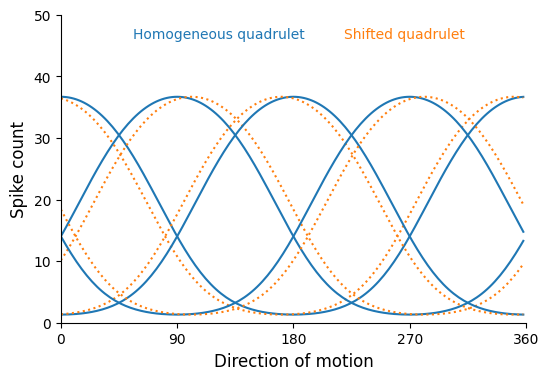

In [216]:
emp_tc_quad = np.array([ssiMod.FTVM_dx(stim, *pars) for pars in simple_pars[bio_idx]])

shifted_mu = final_th[np.array([np.where(stim==i)[0][0] for i in [0,90,180,270]])*10]
shifted_pars = np.copy(simple_pars)
shifted_pars[:,:,1] = np.repeat(shifted_mu[None,:], len(data_dict['all_multipliers']), axis=0)

shifted_tc_quad = np.array([ssiMod.FTVM_dx(stim, *pars) for pars in shifted_pars[bio_idx]])

plt.figure(figsize = (6,4))
for i in range(og_tc_quad.shape[0]):
    if i==0:
        label1 = 'Homogeneous quadrulet'
        label2 = 'Shifted quadrulet'
    else: 
        label1, label2 = '_nolegend_', '_nolegend_'
    plt.plot(stim, emp_tc_quad[i], color = 'tab:blue', label = label1)
    plt.plot(stim, shifted_tc_quad[i], ls='dotted', color = 'tab:orange', label = label2)
    
    plt.xlim(0,360)
    plt.xticks(np.arange(0,361,90))
    plt.ylim(0,50)
    plt.xlabel('Direction of motion', size = 12)
    plt.ylabel('Spike count', size = 12)
    
    plt.legend(handlelength = 0, frameon=0, labelcolor = 'linecolor', ncol=2, loc = 'upper center')
plt.savefig('Quad and Shifted Quad_IdenCells.jpg', bbox_inches = 'tight', dpi = 300)

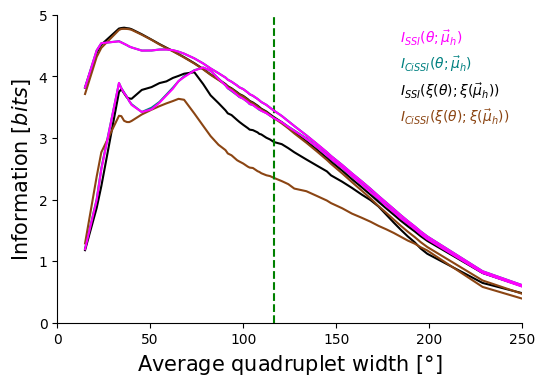

In [218]:
plt.figure(figsize = (6,4))

ex_avg_fwhm = data_dict['all_quad_fwhm'][example].mean(axis=1)
plt.plot(ex_avg_fwhm, og_ssi.min(axis=1), color = 'magenta', label=r'$I_{SSI}(\theta; \vec{\mu}_{h})$', zorder = 4)
plt.plot(ex_avg_fwhm, og_cissi.min(axis=1), color = 'teal', label=r'$I_{CiSSI}(\theta; \vec{\mu}_{h})$')
plt.plot(ex_avg_fwhm, mod_ssi.min(axis=1), color = 'k', label=r'$I_{SSI}(\xi(\theta); \xi(\vec{\mu}_{h}))$')
plt.plot(ex_avg_fwhm, mod_cissi.min(axis=1), color = 'saddlebrown', label=r'$I_{CiSSI}(\xi(\theta); \xi(\vec{\mu}_{h}))$')

plt.plot(ex_avg_fwhm, og_ssi.mean(axis=1), color = 'magenta', zorder = 4)
plt.plot(ex_avg_fwhm, mod_ssi.mean(axis=1), color = 'k')
plt.plot(ex_avg_fwhm, og_cissi.mean(axis=1), color = 'teal')
plt.plot(ex_avg_fwhm, mod_cissi.mean(axis=1), color = 'saddlebrown')


plt.axvline(ex_avg_fwhm[bio_idx], ls='--', color = 'green')

plt.xlabel(r'Average quadruplet width [$\degree$]', size = 15)
plt.ylabel(r'Information [$bits$]', size = 15)

plt.xlim(0,250)
plt.ylim(0,5)

plt.legend(frameon=0, handlelength=0, labelcolor = 'linecolor', ncol = 1, loc= 'upper right')
plt.savefig('Quad_&_Shifted_quad_SSIs_IdenCells.jpg', bbox_inches = 'tight', dpi = 300)

In [15]:
from scipy.signal import find_peaks, savgol_filter
from collections import Counter

In [319]:
main_dir = '/home/cparis/00PhD/'


quad_list = []

#array labelling the biological quadruplets
bio_quad_idx = []

for experiment_number in range(1,8,1):
    experiment_name = f'Exp{experiment_number}'
    datanfits = dict(np.load(main_dir+f'Analysis of {experiment_name}.npz'))
    print(datanfits['quadruplet_combos'].shape)
    quad_list += zip(np.full(len(datanfits['quadruplet_combos']), experiment_number), datanfits['quadruplet_combos'])
#     for each quadruplet
    for quad in datanfits['quadruplet_combos']:
        if quad.tolist() in datanfits['biological_quadruplets'].tolist():
            bio_quad_idx += [True]
        else:  bio_quad_idx+= [False]
bio_quad_idx = np.array(bio_quad_idx)    

data_dict['exp_quad_list'] = quad_list

exp_idx, quad = zip(*data_dict['exp_quad_list'])
quad = np.array(quad)
print('Number of bio quads in:')
for experiment_number in range(1,8,1):
    q = np.count_nonzero(np.array(exp_idx)[bio_quad_idx]==experiment_number)
    print(f'Experiment {experiment_number}: {q}',)

(120, 4)
(18, 4)
(72, 4)
(24, 4)
(160, 4)
(250, 4)
(4, 4)
Number of bio quads in:
Experiment 1: 21
Experiment 2: 0
Experiment 3: 9
Experiment 4: 0
Experiment 5: 33
Experiment 6: 19
Experiment 7: 2


11
Percentage of number of peaks for ALL quadruplets: 
 {1: 0.543, 2: 0.44, 3: 0.017}
Percentage of number of peaks for PROXIMAL quadruplets: 
 {1: 0.536, 2: 0.464, 3: 0.0}


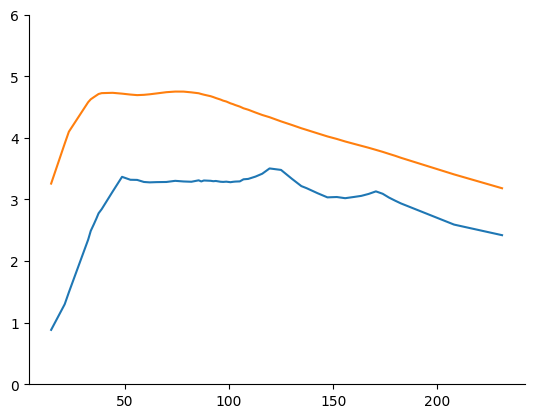

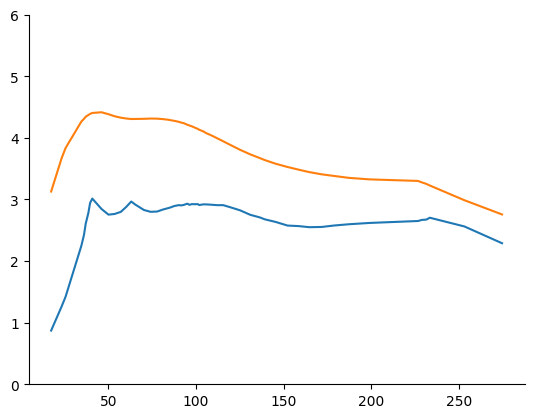

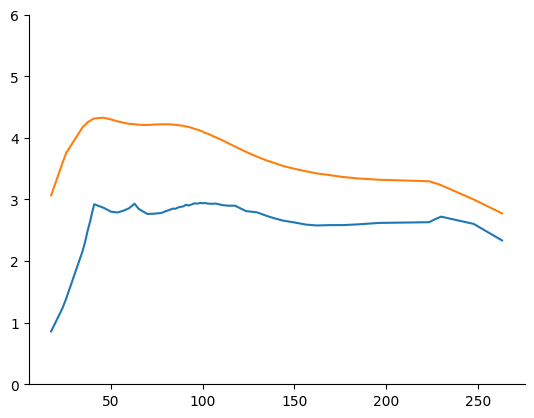

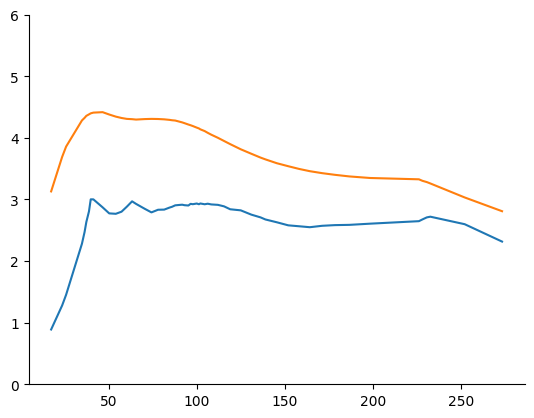

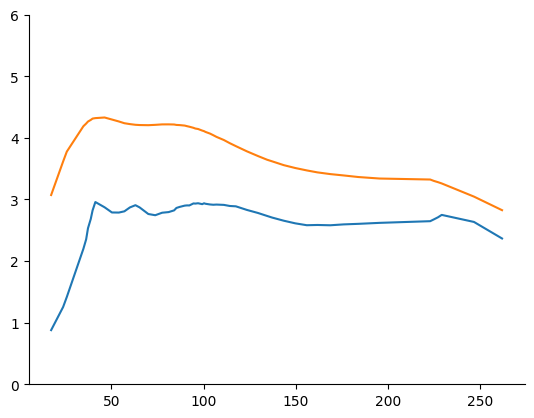

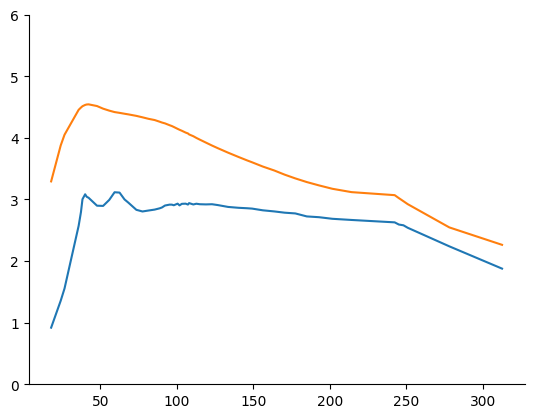

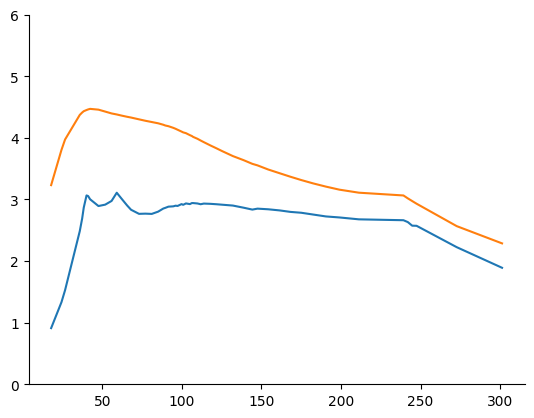

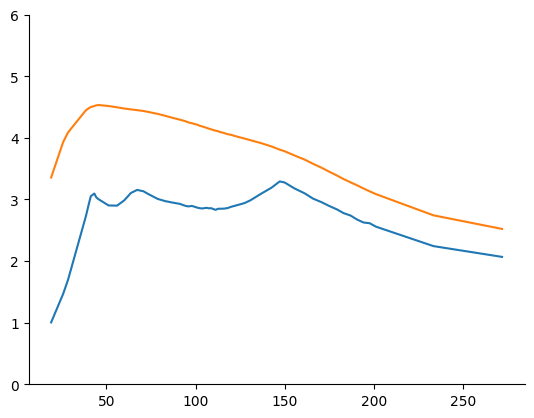

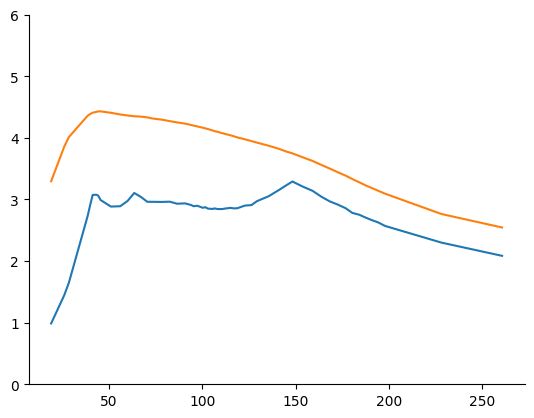

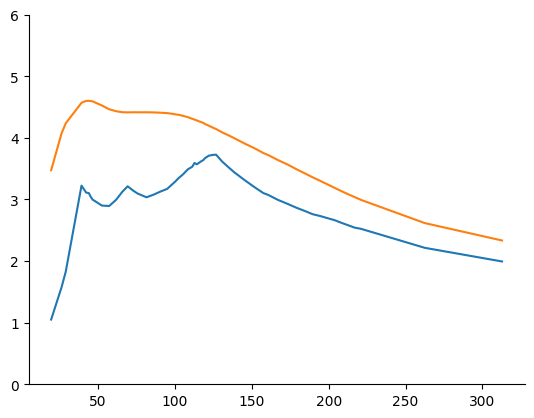

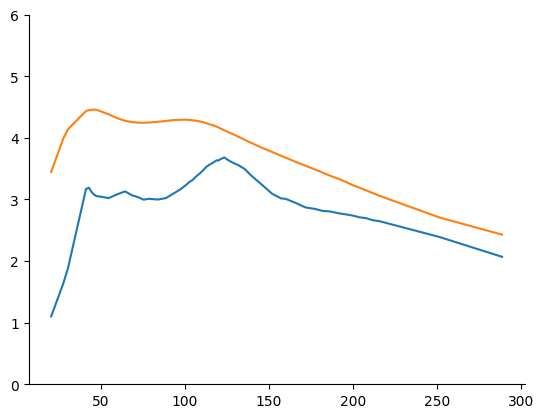

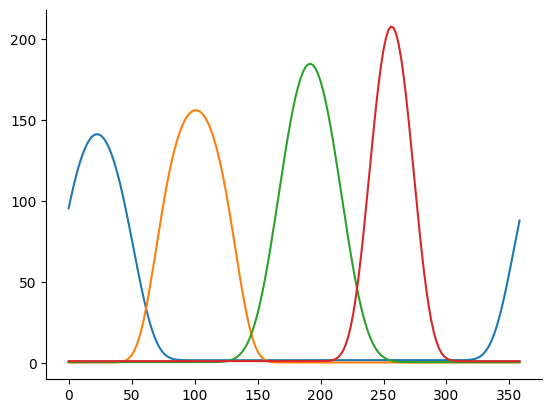

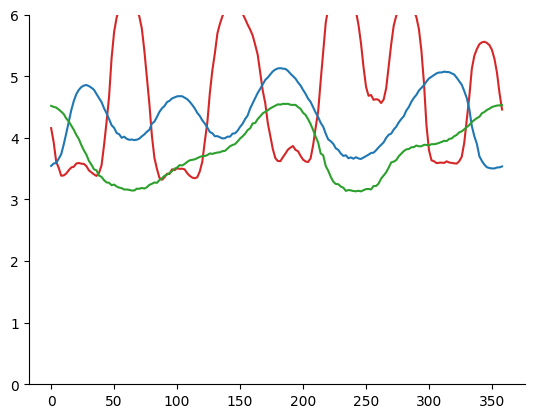

In [335]:
peaks_min = [find_peaks(savgol_filter(quad_ssi.min(axis=1), window_length=3, polyorder=0)[np.where(data_dict['all_quad_fwhm'].mean(axis=2)[i]<=180)], \
                        distance = 5, prominence=0.05)[0] for i,quad_ssi in enumerate(data_dict['all_ssis'])]
peaks_avg = [find_peaks(savgol_filter(quad_ssi.mean(axis=1), window_length=3, polyorder=0)[np.where(data_dict['all_quad_fwhm'].mean(axis=2)[i]<=180)], \
                        distance = 5, prominence=0.05)[0] for i,quad_ssi in enumerate(data_dict['all_ssis'])]

bio_peaks_min = [x for x, b in zip(peaks_min, bio_quad_idx) if b]

lengths = [len(x) for x in peaks_min]
bio_lengths = [len(x) for x in bio_peaks_min]

triple_peak = np.where(np.array(lengths)==3)[0]
print(triple_peak.shape[0])
for idx, _ in enumerate(triple_peak):
    plt.figure()
    plt.plot(data_dict['all_quad_fwhm'].mean(axis=2)[np.where(np.array(lengths)==3)[0][idx]], \
            data_dict['all_ssis'].min(axis=2)[np.where(np.array(lengths)==3)[0][idx]])

    plt.plot(data_dict['all_quad_fwhm'].mean(axis=2)[np.where(np.array(lengths)==3)[0][idx]], \
            data_dict['all_ssis'].mean(axis=2)[np.where(np.array(lengths)==3)[0][idx]])
    plt.ylim(0,6)

# print(peaks_min[np.where(np.array(lengths)==3)[0][0]][2])

plt.figure()
plt.plot(np.arange(0,360,2), data_dict['all_quad_tc'][np.where(np.array(lengths)==3)[0][0], \
                                                      peaks_min[np.where(np.array(lengths)==3)[0][0]][0]].T)
plt.figure()
for k in [0,1,2]:
    plt.plot(np.arange(0,360,2), data_dict['all_ssis'][np.where(np.array(lengths)==3)[0][0], \
                                                      peaks_min[np.where(np.array(lengths)==3)[0][0]][k]],\
            color = ['tab:red', 'tab:blue', 'tab:green'][k])
plt.ylim(0,6)

counts = Counter(lengths)
fractions = {k: np.around(counts.get(k,0)/len(peaks_min),3) for k in [1,2,3]}

bio_counts = Counter(bio_lengths)
bio_fractions = {k: np.around(bio_counts.get(k,0)/len(bio_peaks_min),3) for k in [1,2,3]}

print('Percentage of number of peaks for ALL quadruplets: \n', fractions)
print('Percentage of number of peaks for PROXIMAL quadruplets: \n', bio_fractions)

In [201]:
mod_stim = np.copy(xi_stim)
emp_tcs = np.copy(example_quad_tc)
mod_prior = np.copy(xi_prior)


ssi_og = np.copy(data_dict['all_ssis'][example, bio_idx])
emp_cissi_og = ssiMod.MC_CiSSI(stim, th_prior, emp_tcs)
ssi_og = ssiMod.MC_SSI_w_PRIOR(stim, emp_tcs, th_prior)

emp_cissi_mod = ssiMod.MC_CiSSI(mod_stim, mod_prior, emp_tcs)
emp_ssi_mod = ssiMod.MC_SSI_w_PRIOR(mod_stim, emp_tcs, mod_prior)

0
450
900
1350
0 maroon
450 maroon
900 maroon
1350 maroon


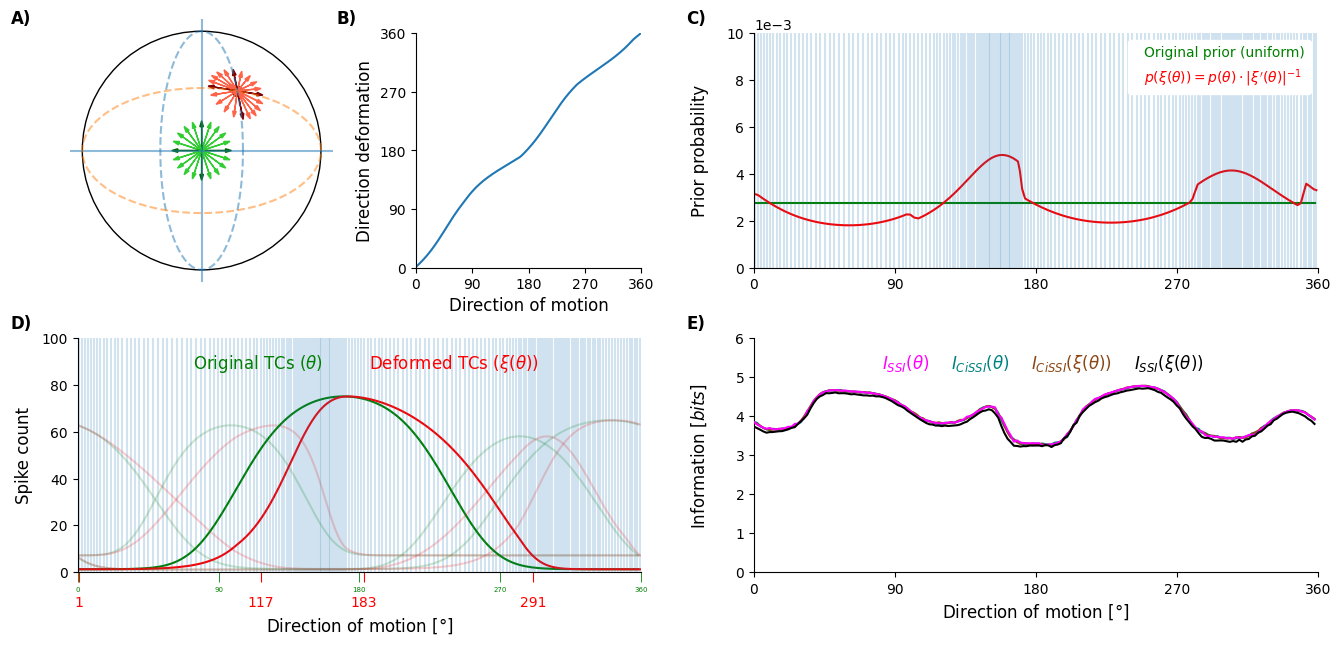

In [203]:
labelsize = 12

fig = plt.figure(figsize=(16,7))

# gs = gridspec.GridSpec(2,4,hspace=0.2, wspace = 0.5)
# make first row taller to match ax2's height
gs = gridspec.GridSpec(2, 4, hspace=0.3, wspace=0.5, height_ratios=[1,1])
# =====================================================
# PANEL 1 (left) (square) — geometry + arrows  
# =====================================================
ax0 = fig.add_subplot(gs[0,0])
# ax0.set_box_aspect(1)
plot_circle(ax0, 90, 1)
draw_ellipse(ax0, vert_a, vert_b)
draw_ellipse(ax0, hor_a, hor_b)
arrow_len = 0.2
ax0.scatter(x0, z0, s=50, c='k')
final_arr=np.array([])
# uniform arrows
for idx, theta in enumerate(np.deg2rad(fine_stim)):
    # upward arrow at (0,0)
    if idx % 90==0:
        if idx%(fine_stim.size//4)==0:
            print(idx)
            arrowcolor='darkgreen'
        else: arrowcolor='limegreen'
        ax0.arrow(0, 0, arrow_len*np.cos(theta),arrow_len*np.sin(theta), 
             head_width=0.03, head_length=0.05, fc=arrowcolor, ec=arrowcolor)
    l_mod_z, th_mod_z = flow_in_point_of_ellipse(x0,z0, vert_a, vert_b, arrow_len*np.sin(theta), 'v')
    l_mod_x, th_mod_x = flow_in_point_of_ellipse(z0,x0, hor_b, hor_a, arrow_len*np.cos(theta), 'h')
    
    resultant = l_mod_x*np.exp(1j*np.deg2rad(th_mod_x)) + l_mod_z*np.exp(1j*np.deg2rad(th_mod_z))
    final_arr = np.append(final_arr, resultant)

final_l, final_th = np.sqrt(final_arr.real**2+final_arr.imag**2), np.rad2deg(np.angle(final_arr))%360 

# arrows already computed externally
for idx, arr in enumerate(final_l*np.exp(1j*np.deg2rad(final_th))):
    if idx % 90==0:
        if idx%(fine_stim.size//4)==0:
            print(idx, 'maroon')
            arrowcolor='maroon'
        else: 
            arrowcolor='tomato'
    else: continue
    ax0.arrow(x0, z0, arr.real, arr.imag,
         head_width=0.03, head_length=0.05, fc=arrowcolor, ec=arrowcolor)
ax0.set_xticks([])
ax0.set_yticks([])
# =====================================================
# PANEL 1 (right) (square) — \xi(\theta)  
# =====================================================
ax1 = fig.add_subplot(gs[0,1])
# ax1.set_box_aspect(1)
ax1.plot(stim, xi_stim)
ax1.set_xlabel(r'Direction of motion', size = labelsize)
ax1.set_ylabel(r'Direction deformation', size = labelsize)
ax1.set_xticks(np.arange(0,361, 90))
ax1.set_yticks(np.arange(0,361, 90))
ax1.set_xlim(0,360)
ax1.set_ylim(0,360)

# =====================================================
# PANEL 2 — prior transformation
# =====================================================
ax2 = fig.add_subplot(gs[0,2:])

ax2.plot(stim, th_prior, color='green', label='Original prior (uniform)')
ax2.plot(xi_stim, xi_prior, color='red',
         label=r'$p(\xi(\theta)) = p(\theta)\cdot |\xi^{\prime}(\theta)|^{-1}$')

ax2.vlines(xi_stim, ymin=0, ymax=0.01, alpha=0.2)

# ax2.set_xlabel(r'Direction of motion [$\degree$]', size=labelsize)
ax2.set_ylabel('Prior probability', size=labelsize)
ax2.yaxis.set_label_coords(-0.08, 0.5)

ax2.set_xticks(np.arange(0,361,90))
ax2.set_xlim(0,360)
ax2.set_ylim(0,0.01)

ax2.ticklabel_format(axis='y', style='sci', scilimits=(-3,-3))

leg = ax2.legend(handlelength=0,
                 labelcolor='linecolor',
                 edgecolor='w',
                 facecolor='white',
                 framealpha=1)

ax2.text(-0.12, 1.1, 'C)', ha='left', va='top', transform=ax2.transAxes, fontweight='bold', fontsize = labelsize)
# =====================================================
# PANEL 3 — tuning curves
# =====================================================
ax3 = fig.add_subplot(gs[1,:2])

for i in range(emp_tcs.shape[0]):

    if i == 2:
        label1 = r'Original TCs ($\theta$)'
        label2 = r'Deformed TCs ($\xi(\theta)$)'
        alpha = 1
    else:
        label1 = '_nolegend_'
        label2 = '_nolegend_'
        alpha = 0.2

    ax3.plot(stim, emp_tcs[i] + 0.025,
             color='green', alpha=alpha, label=label1)

    ax3.plot(xi_stim, emp_tcs[i],
             color='red', alpha=alpha, label=label2)

ax3.set_xlim(0,360)
ax3.set_ylim(0,100)

ax3.set_xlabel('Direction of motion [$\degree$]', size=labelsize)
ax3.set_ylabel('Spike count', size=labelsize)

ax3.set_yticks(np.arange(0,101,20))

ax3.vlines(xi_stim, ymin=0, ymax=100, alpha=0.2)

ax3.tick_params(axis='x', size=7, labelsize=10,
                which='major', color='red', labelcolor='red', pad=10)

ax3.tick_params(axis='x', size=7, labelsize=5,
                which='minor', color='green', labelcolor='green')

ax3.set_xticks(
    np.around(xi_stim[np.array([np.where(stim==v)[0][0] for v in [0,90,180,270]])])
)

ax3.set_xticks(np.arange(0,361,90), np.arange(0,361,90), minor=True)
ax3.yaxis.set_label_coords(-0.08, 0.5)
leg = ax3.legend(handlelength=0,
                 labelcolor='linecolor',
                 frameon=0,
                 fontsize=12,
                 ncol=2,
                 loc='upper center')

ax3.text(-0.12, 1.1, 'D)', ha='left', va='top', transform=ax3.transAxes, fontweight='bold', fontsize = labelsize)

# =====================================================
# PANEL 4 — information comparison (broken axis)
# =====================================================
# bax = brokenaxes(
#     subplot_spec=gs[1,2:],
#     ylims=((0,0.1),(2,5)),
#     hspace=0.05
# )

bax = fig.add_subplot(gs[1,2:])

bax.plot(stim, ssi_og, color='magenta', label=r'$I_{SSI}(\theta)$', zorder = 3)
bax.plot(stim, emp_cissi_og, color='teal', label=r'$I_{CiSSI}(\theta)$', zorder = 1)
bax.plot(stim, emp_cissi_mod, color='saddlebrown', label=r'$I_{CiSSI}(\xi(\theta))$', zorder = 2)
bax.plot(stim, emp_ssi_mod, color='black', label=r'$I_{SSI}(\xi(\theta))$', zorder = 4)

bax.set_yticks(np.arange(0,6.1,1))
bax.set_ylim(0,6)

bax.set_xticks(np.arange(0,361,90))
bax.set_xlim(0,360)

bax.set_xlabel(r'Direction of motion [$\degree$]', size=labelsize)
bax.set_ylabel(r'Information [$bits$]', size=labelsize)
bax.yaxis.set_label_coords(-0.08, 0.5)

bax.legend(handlelength=0,
           labelcolor='linecolor',
           frameon=0,
           fontsize=labelsize,
           ncol=4,
           columnspacing = .5,
           loc='upper center')

bax.text(-0.12, 1.1, 'E)', ha='left', va='top', \
                transform=bax.transAxes, fontweight='bold', fontsize = labelsize)

# ax0.set_position([0.12, 0.632, 0.325, 0.325])  # [left, bottom, width, height]
# ax0.text(-0.265, 1.18, 'A)', ha='left', va='top', transform=ax0.transAxes, fontweight='bold', fontsize = labelsize)

ax0.set_position([0.015, 0.525, 0.375, 0.375])  # [left, bottom, width, height]
ax0.text(-0.227, 1.0375, 'A)', ha='left', va='top', transform=ax0.transAxes, fontweight='bold', fontsize = labelsize)
ax1.text(-0.35, 1.1, 'B)', ha='left', va='top', transform=ax1.transAxes, fontweight='bold', fontsize = labelsize)


plt.savefig(f'Flow_CiSSi_v_SSI_quad_{example}.jpg', dpi=400, bbox_inches='tight')

AttributeError: 'FancyArrow' object has no property 'arrowstyle'

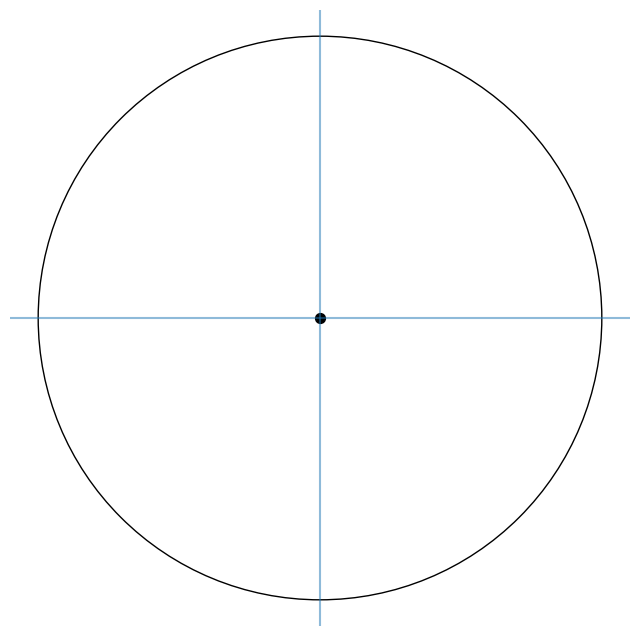

In [14]:
stim = np.arange(0,360,90)
fine_stim = np.arange(0,360,90)
labelsize = 12
R=1


fig = plt.figure(figsize=(8,8))

# gs = gridspec.GridSpec(2,4,hspace=0.2, wspace = 0.5)
# make first row taller to match ax2's height
gs = gridspec.GridSpec(1, 1)
# =====================================================
# PANEL 1 (left) (square) — geometry + arrows  
# =====================================================
ax0 = fig.add_subplot(gs[0,0])
# ax0.set_box_aspect(1)

for x0 in np.arange(0,0.9, 0.1):
    if np.sqrt(x0**2+z0**2)>R: break
    z0=x0
    vert_b, vert_a = 1, flow_ellipse_axis(x0,z0)
    hor_a, hor_b = 1, flow_ellipse_axis(z0,x0)
    plot_circle(ax0, 90, 1)
    # draw_ellipse(ax0, vert_a, vert_b)
    # draw_ellipse(ax0, hor_a, hor_b)
    arrow_len = 0.2
    ax0.scatter(x0, z0, s=50, c='k')
    final_arr=np.array([])
    # uniform arrows
    for idx, theta in enumerate(np.deg2rad(fine_stim)):
        # upward arrow at (0,0)
        ax0.arrow(0, 0, arrow_len*np.cos(theta),arrow_len*np.sin(theta), 
             head_width=0.03, head_length=0.05, fc='green', ec='green', arrowstyle ='->')
        l_mod_z, th_mod_z = flow_in_point_of_ellipse(x0,z0, vert_a, vert_b, arrow_len*np.sin(theta), 'v')
        l_mod_x, th_mod_x = flow_in_point_of_ellipse(z0,x0, hor_b, hor_a, arrow_len*np.cos(theta), 'h')

        resultant = l_mod_x*np.exp(1j*np.deg2rad(th_mod_x)) + l_mod_z*np.exp(1j*np.deg2rad(th_mod_z))
        final_arr = np.append(final_arr, resultant)

    final_l, final_th = np.sqrt(final_arr.real**2+final_arr.imag**2), np.rad2deg(np.angle(final_arr))%360 

    # arrows already computed externally
    for idx, arr in enumerate(final_l*np.exp(1j*np.deg2rad(final_th))):
#         if idx % 90==0:
#             if idx%(fine_stim.size//4)==0:
#                 print(idx, 'maroon')
#                 arrowcolor='maroon'
#             else: 
#                 arrowcolor='tomato'
#         else: continue
        ax0.arrow(x0, z0, arr.real, arr.imag,
             head_width=0.03, head_length=0.05, fc=arrowcolor, ec=arrowcolor)
    ax0.set_xticks([])
    ax0.set_yticks([])